# De neurona por neurona a matmul

El mismo cálculo de una red (4 entradas → 3 ocultas → 1 salida) escrito en tres niveles de abstracción:

1. **A mano:** una variable por neurona y por peso.
2. **Con funciones:** `dense` para una capa y `sequential` para la red.
3. **Vectorizado:** una multiplicación de matrices por capa.

Los tres producen exactamente el mismo resultado; cambia el código, no la matemática.

### Nivel 1: una variable por cada cosa

Si se quiere escribir cada neurona explícitamente, cada peso necesita su nombre: `w1_1` (capa 1, neurona 1), `b1_1`, `z1_1` y `a1_1`. Con 4 entradas y 3 neuronas ocultas ya son 3 vectores de pesos, 3 sesgos y 3 activaciones; y falta la capa de salida. La celda siguiente lo escribe completo para que se vea el tamaño real del problema.

In [1]:
import numpy as np

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Entrada: 4 features de un solo ejemplo
x = np.array([0.5, 0.8, 0.2, 0.1])

# ===== Capa 1, escrita neurona por neurona =====
w1_1 = np.array([0.4, -0.3, 0.2, 0.5])
b1_1 = 0.1
z1_1 = np.dot(w1_1, x) + b1_1
a1_1 = sigmoid(z1_1)

w1_2 = np.array([0.1, 0.6, -0.2, 0.3])
b1_2 = -0.1
z1_2 = np.dot(w1_2, x) + b1_2
a1_2 = sigmoid(z1_2)

w1_3 = np.array([-0.5, 0.2, 0.4, -0.1])
b1_3 = 0.05
z1_3 = np.dot(w1_3, x) + b1_3
a1_3 = sigmoid(z1_3)

# ===== Capa 2, una sola neurona =====
a1 = np.array([a1_1, a1_2, a1_3])
w2_1 = np.array([0.7, -0.4, 0.5])
b2_1 = 0.2
z2_1 = np.dot(w2_1, a1) + b2_1
a2_1 = sigmoid(z2_1)

print(f"a1 = [{a1_1:.3f}, {a1_2:.3f}, {a1_3:.3f}]")
print(f"salida final = {a2_1:.3f}")
print(f"Variables creadas a mano: {len([w1_1, b1_1, z1_1, a1_1, w1_2, b1_2, z1_2, a1_2, w1_3, b1_3, z1_3, a1_3, w2_1, b2_1, z2_1, a2_1])} (y la red tiene solo 3 neuronas ocultas)")

a1 = [0.537, 0.603, 0.507]
salida final = 0.643
Variables creadas a mano: 16 (y la red tiene solo 3 neuronas ocultas)


### Nivel 2: funciones `dense` y `sequential`

El patrón se repite idéntico en cada neurona, así que se encapsula:

- **`dense(a_in, W, b)`**: recibe la entrada, la matriz de pesos (una fila por neurona) y el vector de sesgos; recorre las neuronas y devuelve el vector de activaciones.
- **`sequential(x)`**: encadena las capas — `a1 = dense(x, W1, b1)`, luego `a2 = dense(a1, W2, b2)` — hasta la salida.

Es el mismo cálculo del nivel 1, pero la red ya se arma con dos llamadas en vez de decenas de variables.

In [2]:
import numpy as np

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

def dense(a_in, W, b):
    """
    Calcula una capa completa neurona por neurona.
    Args:
      a_in (ndarray (n,)): activaciones de la capa anterior
      W (ndarray (unidades, n)): una fila de pesos por neurona
      b (ndarray (unidades,)): un sesgo por neurona
    Returns:
      a_out (ndarray (unidades,)): activaciones de esta capa
    """
    unidades = W.shape[0]
    a_out = np.zeros(unidades)
    for j in range(unidades):
        z = np.dot(W[j], a_in) + b[j]
        a_out[j] = sigmoid(z)
    return a_out

# La misma red del nivel 1, ahora en matrices
x = np.array([0.5, 0.8, 0.2, 0.1])
W1 = np.array([[0.4, -0.3, 0.2, 0.5],
               [0.1, 0.6, -0.2, 0.3],
               [-0.5, 0.2, 0.4, -0.1]])
b1 = np.array([0.1, -0.1, 0.05])
W2 = np.array([[0.7, -0.4, 0.5]])
b2 = np.array([0.2])

def sequential(x):
    """Encadena las capas hasta la salida final."""
    a1 = dense(x, W1, b1)
    a2 = dense(a1, W2, b2)
    return a2

a1_dense = dense(x, W1, b1)
a2_dense = sequential(x)
print(f"a1 = {np.round(a1_dense, 3)}")
print(f"salida final = {a2_dense[0]:.3f}")
print(f"¿Igual que a mano? {np.allclose(a1_dense, np.array([0.537, 0.603, 0.507]), atol=1e-3)}")

a1 = [0.537 0.603 0.507]
salida final = 0.643
¿Igual que a mano? True


### Nivel 3: vectorización con `matmul`

El bucle de `dense` también se puede eliminar. Si `W` tiene una fila por neurona, entonces `W @ a_in` calcula **todos los puntajes a la vez**: cada fila se multiplica por el vector de entrada y produce un número. Sumar `b` y aplicar la sigmoide elemento a elemento completa la capa.

`@` es el operador de multiplicación de matrices (equivale a `np.matmul`). Tres operaciones por capa, sin bucle, con el mismo resultado.

In [3]:
import numpy as np

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

def dense_vectorizado(a_in, W, b):
    """Una capa completa en una sola multiplicación de matrices."""
    return sigmoid(W @ a_in + b)

x = np.array([0.5, 0.8, 0.2, 0.1])
W1 = np.array([[0.4, -0.3, 0.2, 0.5],
               [0.1, 0.6, -0.2, 0.3],
               [-0.5, 0.2, 0.4, -0.1]])
b1 = np.array([0.1, -0.1, 0.05])
W2 = np.array([[0.7, -0.4, 0.5]])
b2 = np.array([0.2])

a1_vec = dense_vectorizado(x, W1, b1)
a2_vec = dense_vectorizado(a1_vec, W2, b2)
print(f"a1 = {np.round(a1_vec, 3)}")
print(f"salida final = {a2_vec[0]:.3f}")
print(f"¿Igual que con dense en bucle? {np.allclose(a1_vec, a1_dense)}")
print(f"¿Igual que a mano? {np.allclose(a2_vec[0], a2_1, atol=1e-9)}")

a1 = [0.537 0.603 0.507]
salida final = 0.643
¿Igual que con dense en bucle? True
¿Igual que a mano? True


### Apéndice OPCIONAL: cómo multiplica matrices `matmul`

Si nunca se vio álgebra lineal, esta parte se puede saltar sin problema: el código de arriba funciona igual. La idea, en una frase: **cada número del resultado es una fila de la izquierda multiplicada por una columna de la derecha, sumando los productos**.

Con $A$ de forma $(m, n)$ y $B$ de forma $(n, p)$, el resultado es $(m, p)$. La $n$ interna debe coincidir: son las piezas que se multiplican y se suman. Si no coincide, la operación no está definida. En una capa densa, cada fila de $W$ es una neurona y $a_{in}$ es una columna: de ahí sale un puntaje por neurona.

A @ B =
[[19. 22.]
 [43. 50.]]
C[0,0] = 1.0*5.0 + 2.0*7.0 = 19 (fila 1 por columna 1)


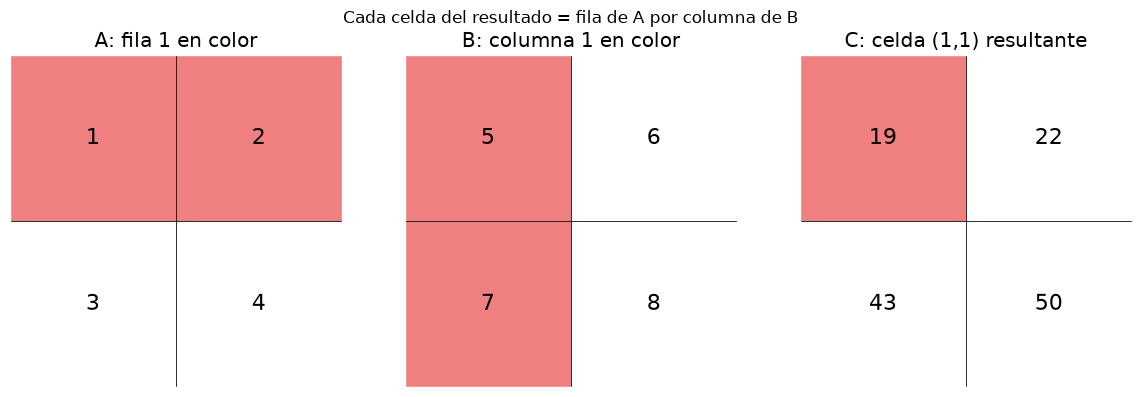

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

# Paso: fila por columna sobre matrices 2x2
A = np.array([[1.0, 2.0],
              [3.0, 4.0]])
B = np.array([[5.0, 6.0],
              [7.0, 8.0]])
C = A @ B
print(f"A @ B =\n{C}")
print(f"C[0,0] = {A[0,0]}*{B[0,0]} + {A[0,1]}*{B[1,0]} = {C[0,0]:.0f} (fila 1 por columna 1)")

# Guía visual: la fila 1 de A y la columna 1 de B producen C[0,0]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, M, titulo in [(axes[0], A, "A: fila 1 en color"),
                      (axes[1], B, "B: columna 1 en color"),
                      (axes[2], C, "C: celda (1,1) resultante")]:
    ax.imshow(np.zeros_like(M), cmap='Greys', vmin=0, vmax=1)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            color = 'lightcoral' if (ax is axes[0] and i == 0) or (ax is axes[1] and j == 0) or (ax is axes[2] and i == 0 and j == 0) else 'white'
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor='k'))
            ax.text(j, i, f"{M[i, j]:.0f}", ha='center', va='center', fontsize=16)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(-0.5, M.shape[1] - 0.5)
    ax.set_ylim(M.shape[0] - 0.5, -0.5)
plt.suptitle("Cada celda del resultado = fila de A por columna de B")
plt.tight_layout()
plt.show()

### Cierre

Tres escrituras, un solo cálculo: a mano (didáctico pero insostenible), con `dense` y `sequential` (reutilizable) y con `matmul` (el estándar de la industria, porque además cabe entero en GPU). El apéndice de álgebra es opcional: lo único que hace falta recordar es que `W @ a` produce un puntaje por fila de `W`, y cada fila es una neurona.